In [1]:
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/impport_packages.ipynb"    #import all necessary packages - numpy, pandas etc
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/simulation_class.ipynb"    #import all necessary packages - numpy, pandas etc
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/create_world.ipynb"

#### Set up sim essentials

The onlything modified here is the `run_simulation` function

Redifine `run simulation` without the rho and m subsets + proper seeding for replicates

In [ ]:
def create_cube(popsize, dims, nof_dimensions, epsilon=0.1, initial_memory=-3):
    """
    Create and initialize a population cube N with genotype, phenotype,
    and developmental layers.

    Parameters:
        popsize (int): Number of individuals in the population.
        dims (dict): Output from get_cube_dims().
        nof_dimensions (int): Number of dimensions (traits).
        epsilon (float): Random noise factor for phenotype initialization.

    Returns:
        np.ndarray: Initialized cube with dimensions [popsize, total_layers].
    """
    # Initialize cube
    N = np.empty((popsize, dims['total_layers']))
    
    # Initialize memory & neutral layers
    N[:, dims['memory']:dims['neutral'] + 1] = initial_memory

    # Initialize genotype layer
    N[:, dims['geno']] = np.zeros((popsize, nof_dimensions))

    # Initialize phenotype layer with mut
    N[:, dims['pheno']] = N[:, dims['geno']] + epsilon * np.random.randn(popsize, nof_dimensions)

    # Initialize development layer with NaN
    N[:, dims['dev']] = np.nan

    return N


In [2]:
def run_simulation(params):
    scenarios, seed, popsize, maxgen, dims, N, mutsize, mutrate, epsilon, nof_dimensions, only_genetics = params
    
    rho_m_alpha_beta = scenarios[0:4]
    env_states = scenarios[4:]
    
    np.random.seed(seed)
    print(f"Using seed: {seed}")
    

    meanw = np.zeros(maxgen)
    meanw0 = np.zeros(maxgen)
    meanw1 = np.zeros(maxgen)
    meanmemory_g = np.zeros(maxgen)
    meanmemory_p= np.zeros(maxgen)
    meanneutral_g = np.zeros(maxgen)
    meanneutral_p = np.zeros(maxgen)
    mean_gen = np.zeros(maxgen)
    mean_pheno = np.zeros((nof_dimensions, maxgen))
    norm = np.zeros(maxgen)
    
    for t in range(0, (maxgen-1)):
        #if t%10 == 0:
        #    print(t)
        for d in range(0, nof_dimensions):
            N[:,dims['dev'][d]] = N[:,dims['pheno'][d]] - env_states[t]
            
        
        dist_from_optima = np.sqrt(np.sum(N[:,dims['dev']]**2, axis =1))
        
        #------distance correction ------
        def between_optima_dist(dims):
            multi_d_diff = np.ones(dims) - np.zeros(dims)
            
            return np.sqrt(np.sum(multi_d_diff**2))
        #-----------------------------
        norm_t = between_optima_dist(nof_dimensions) 
        normalised_dist = dist_from_optima/between_optima_dist(nof_dimensions) 
        
        #Distances from either optima
        Dist0 = np.sqrt(np.sum((N[:,dims['pheno']] - 0)**2, axis = 1))/between_optima_dist(nof_dimensions)
        Dist1 = np.sqrt(np.sum((N[:,dims['pheno']] - 1 )**2, axis =1 )) /between_optima_dist(nof_dimensions)
        
        W = np.exp((-normalised_dist**2)/ (2))
        W0 = np.exp((-Dist0**2)/ (2))
        W1 = np.exp((-Dist1**2)/ (2))
        
        meanw[t] = np.mean(W)    
        meanw0[t] = np.mean(W0)
        meanw1[t] = np.mean(W1)
        meanmemory_g[t] = np.mean(N[:, dims['memory']])  # the actual memory
        meanmemory_p[t] = np.mean(1/(1 + np.exp(-N[:,dims['memory']]))) #with the logistc correction
        norm[t] = norm_t
        meanneutral_g[t] = np.mean(N[:,dims['neutral']])
        meanneutral_p[t] = np.mean(1/(1 + np.exp(-N[:,dims['neutral']])))
        mean_gen[t] = np.mean(N[:,dims['geno']])



        mean_pheno[:, t] = [np.mean(N[:, dims['pheno'][i]]) for i in range(nof_dimensions)]

        
        #current gen offspring (the cube gets stored here per gen)
        
        offspring = np.zeros((popsize, dims['total_layers'])) # empty 3D matrix with dimensions of the cube
        
        #sample offspring for each scenario weighted by fitness
        
        
        parents_idx = np.random.choice(popsize, size=popsize, p = (W/np.sum(W)) )#pick #popsize sized random numbers
        offspring[:,:] = N[parents_idx, :] #similar to how it works in matlab
        
        mutate_memories = np.random.uniform(low=0, high=1, size= popsize) < mutrate[0]
        #mutate_neutral = np.random.uniform(low=0, high=1, size=popsize) < mutrate[0]
        mutate_geno = np.random.uniform(low=0, high=1, size=(popsize, nof_dimensions)) < mutrate[1]
        
        # adding a mutation of size mutsize[1], rate mutate_memories, to the epi-memory
        # the epignetic memory evolves; 
        
        offspring[:,dims['memory']] = (
                                offspring[:,dims['memory']] 
                                + mutate_memories * np.random.normal(0, mutsize[0], popsize)
        )
        
        # adding a mutation of size mutsize[1] (epi-mutation size), rate mutate_memories, to the neutral phenotype
        # the neutral trait recieves random mutation but is not implemented in the calculation for fitness; so is evolving neutrally
        offspring[:,dims['neutral']] = (
                                offspring[:,dims['neutral']]  
                                + mutate_memories * np.random.normal(0, mutsize[0], popsize)
        ) 
        
        # adding a mutation of size mutsize[2] (genetic mutation size), rate mutate_memories, to the genotype

        offspring[:,dims['geno']] = (
                            offspring[:,dims['geno']] 
                            + mutate_geno * np.random.normal(0, mutsize[1], size=(popsize, nof_dimensions) )
        )
        
        
        # Construct the phenotype
        if only_genetics :
            if t % 10000 == 0:
                print(f"Gen {t}: Running ONLY genetics mode")
            
            for i in range(0, nof_dimensions):
                offspring[:, dims['pheno'][i]] = (
                offspring[:, dims['geno'][i]]
                + np.random.normal(0, epsilon, size=popsize) )
        else:
            if t % 10000 == 0:
                print(f"Gen {t}: Running EPIGENETIC mode")
            
            for i in range(0, nof_dimensions):
                    offspring[:, dims['pheno'][i]] = (
                        offspring[:, dims['geno'][i]] #genotype
                        + np.random.normal(0, epsilon, size=popsize) # adding random noise (developemental noise, nromally distributed with epsilon variance)
                        + ((1 / (1 + np.exp(-offspring[:, dims['memory']]))) #phenotype version of the memory (y axis) 
                        * (N[parents_idx, dims['pheno'][i]] - N[parents_idx, dims['geno'][i]]))# adding the deviation -> read as weight (phenotypic component * deviation)
                    )
        N = offspring
        
        
    return {
        'rho_m_alpha_beta': rho_m_alpha_beta,
        'maxgen_popsize': [maxgen, popsize],
        'meanw': meanw,
        'norm_t': norm,
        'meanw0': meanw0,
        'meanw1': meanw1,
        'meanmemory_p': meanmemory_p,
        'meanneutral_p': meanneutral_p,
        'mean_pheno': mean_pheno  # New: (nof_dimensions, maxgen)
    }
        

Model params

In [3]:
popsize = 5000

# Mutation rates: [epi-memory mutation rate, geno mutation rate]
mutrate = [0.001, 0.001]

# Mutation sizes: [epi-memory mutation size, geno mutation size]
mutsize = [1, 1]

epsilon = 0.05# phenotypic noise
                                 
initial_memory = 0

results_array = {}  ### DONT FORGET TO RUN BEFORE NEW PARAM CONDITIONS

mutrate[0]*mutsize[0]

maxgen = 10000




#### Define stochastically changing environment

In [4]:
def create_world_single(rho,m, max_gen):

    # Define rho and m grid
    rho = rho
    m = m
    alpha = (1 - rho) * (1 - m)
    beta = (1 - rho) * m


    # Flatten and create DataFrame
    data_env = np.array([rho, m, alpha, beta])

    n_gen = max_gen


    opt = np.array([0, 1])

    Env = np.zeros(n_gen, dtype=int)
    p = np.random.uniform(0, 1, n_gen)

    for g in range(n_gen - 1):
        if p[g] < (alpha if Env[g] == 0 else beta):
            Env[g+1] = 1 - Env[g]  # Flip state
        else:
            Env[g+1] = Env[g]       # Stay same

    env_values = opt[Env] # final result

    
    rho_m_alpha_beta = data_env

    # Equilibrium stats
    return rho_m_alpha_beta, env_values

In [5]:
rho_val_0, m_val_0 = 0.98, 0.98
rho_val_1, m_val_1 = 0.90, 0.51
rho_val_2, m_val_2 = 0.81,0.81
rho_val_3, m_val_3 = -0.65, 0.5


In [ ]:

rho_m_alpha_beta_0, single_scenario_0 = create_world_single(rho =rho_val_0, m= m_val_0, max_gen= maxgen)  # Shape: (10000,)

# First create single scenario,


rho_m_alpha_beta_1, single_scenario_1 = create_world_single(rho =rho_val_1, m= m_val_1, max_gen= maxgen)  # Shape: (10000,)

# First create single scenario,

rho_m_alpha_beta_2, single_scenario_2 = create_world_single(rho =rho_val_2, m= m_val_2, max_gen= maxgen)  # Shape: (10000,)


rho_m_alpha_beta_3, single_scenario_3 = create_world_single(rho =rho_val_3, m= m_val_3, max_gen= maxgen)  # Shape: (10000,)



# Then tile n_reps times to get the array for the replicates
n_reps = 10

Env_stoch = np.vstack([
    np.hstack((
        np.tile(rho_m_alpha_beta_0, (n_reps, 1)),  # (10, 10000)
        np.tile(single_scenario_0, (n_reps, 1))    # (10, 10000)
    )),
    np.hstack((
        np.tile(rho_m_alpha_beta_1, (n_reps, 1)),
        np.tile(single_scenario_1, (n_reps, 1))
    )),
    np.hstack((
        np.tile(rho_m_alpha_beta_2, (n_reps, 1)),
        np.tile(single_scenario_2, (n_reps, 1))
    )),
    
    np.hstack((
        np.tile(rho_m_alpha_beta_3, (n_reps, 1)),
        np.tile(single_scenario_3, (n_reps, 1))
    ))
])




array([[ 9.80e-01,  9.80e-01,  4.00e-04, ...,  0.00e+00,  0.00e+00,
         0.00e+00],
       [ 9.80e-01,  9.80e-01,  4.00e-04, ...,  0.00e+00,  0.00e+00,
         0.00e+00],
       [ 9.80e-01,  9.80e-01,  4.00e-04, ...,  0.00e+00,  0.00e+00,
         0.00e+00],
       ...,
       [-6.50e-01,  5.00e-01,  8.25e-01, ...,  0.00e+00,  1.00e+00,
         0.00e+00],
       [-6.50e-01,  5.00e-01,  8.25e-01, ...,  0.00e+00,  1.00e+00,
         0.00e+00],
       [-6.50e-01,  5.00e-01,  8.25e-01, ...,  0.00e+00,  1.00e+00,
         0.00e+00]], shape=(40, 10004))

### Run the simulations parallely

Create `cube` to store results

#### Stochastically changing environmnet

### Single Trait

In [7]:
onlygen = False

# Number of dimensions (can be 1 or more)
nof_dimensions = 1

# get the cube dimensions
dims = get_cube_dims(nof_dimensions)

#create the cube
N = create_cube(popsize, dims=dims, nof_dimensions=nof_dimensions, epsilon=epsilon, initial_memory=initial_memory)

print(N.shape)


### Define seed_array
seed_array = np.linspace(0, 10000, num=4*n_reps, dtype=int)

if __name__ == '__main__':
    
    # Create all combinations of sigma_mut and sigma_alpha
    param_grid = [
        (scenario, seed, popsize, maxgen, dims, N, mutsize, mutrate, epsilon, nof_dimensions, False) #only genetics can either be True or false
        for scenario, seed in zip(Env_stoch, seed_array) #where each row corresponds to one scenario
    ]

    num_cpus = 13
    
    with concurrent.futures.ProcessPoolExecutor(num_cpus) as executor: 
        results_array_stoch1 = list(executor.map(run_simulation, param_grid))

(5000, 5)
Using seed: 0Using seed: 256
Using seed: 512
Using seed: 769
Using seed: 1025
Using seed: 1282

Gen 0: Running EPIGENETIC modeGen 0: Running EPIGENETIC modeUsing seed: 1538Gen 0: Running EPIGENETIC modeGen 0: Running EPIGENETIC mode




Using seed: 1794Gen 0: Running EPIGENETIC modeUsing seed: 2051
Using seed: 2564Using seed: 2307
Using seed: 2820
Gen 0: Running EPIGENETIC mode

Gen 0: Running EPIGENETIC mode

Gen 0: Running EPIGENETIC modeGen 0: Running EPIGENETIC mode


Gen 0: Running EPIGENETIC modeUsing seed: 3076Gen 0: Running EPIGENETIC mode


Gen 0: Running EPIGENETIC mode
Gen 0: Running EPIGENETIC mode
Using seed: 3333
Gen 0: Running EPIGENETIC mode
Using seed: 3589
Gen 0: Running EPIGENETIC mode
Using seed: 3846
Gen 0: Running EPIGENETIC mode
Using seed: 4102
Gen 0: Running EPIGENETIC mode
Using seed: 4358
Gen 0: Running EPIGENETIC mode
Using seed: 4615
Gen 0: Running EPIGENETIC mode
Using seed: 4871
Gen 0: Running EPIGENETIC mode
Using seed: 5128
Gen 0: Running EPIG

In [10]:
#Collect keys of all the list objects 
keys = list(results_array_stoch1[0].keys())

concatenated_results_epi_stoch_1 = {}


for k in keys:
        concatenated_results_epi_stoch_1[k] = np.vstack([r[k] for r in results_array_stoch1])


In [11]:
norm = concatenated_results_epi_stoch_1['norm_t']
meanmemory_p = concatenated_results_epi_stoch_1['meanmemory_p']
fitness = concatenated_results_epi_stoch_1['meanw']
fitness0 = concatenated_results_epi_stoch_1['meanw0']
fitness1 = concatenated_results_epi_stoch_1['meanw1']
phenotype = concatenated_results_epi_stoch_1['mean_pheno']  # Assuming this exists


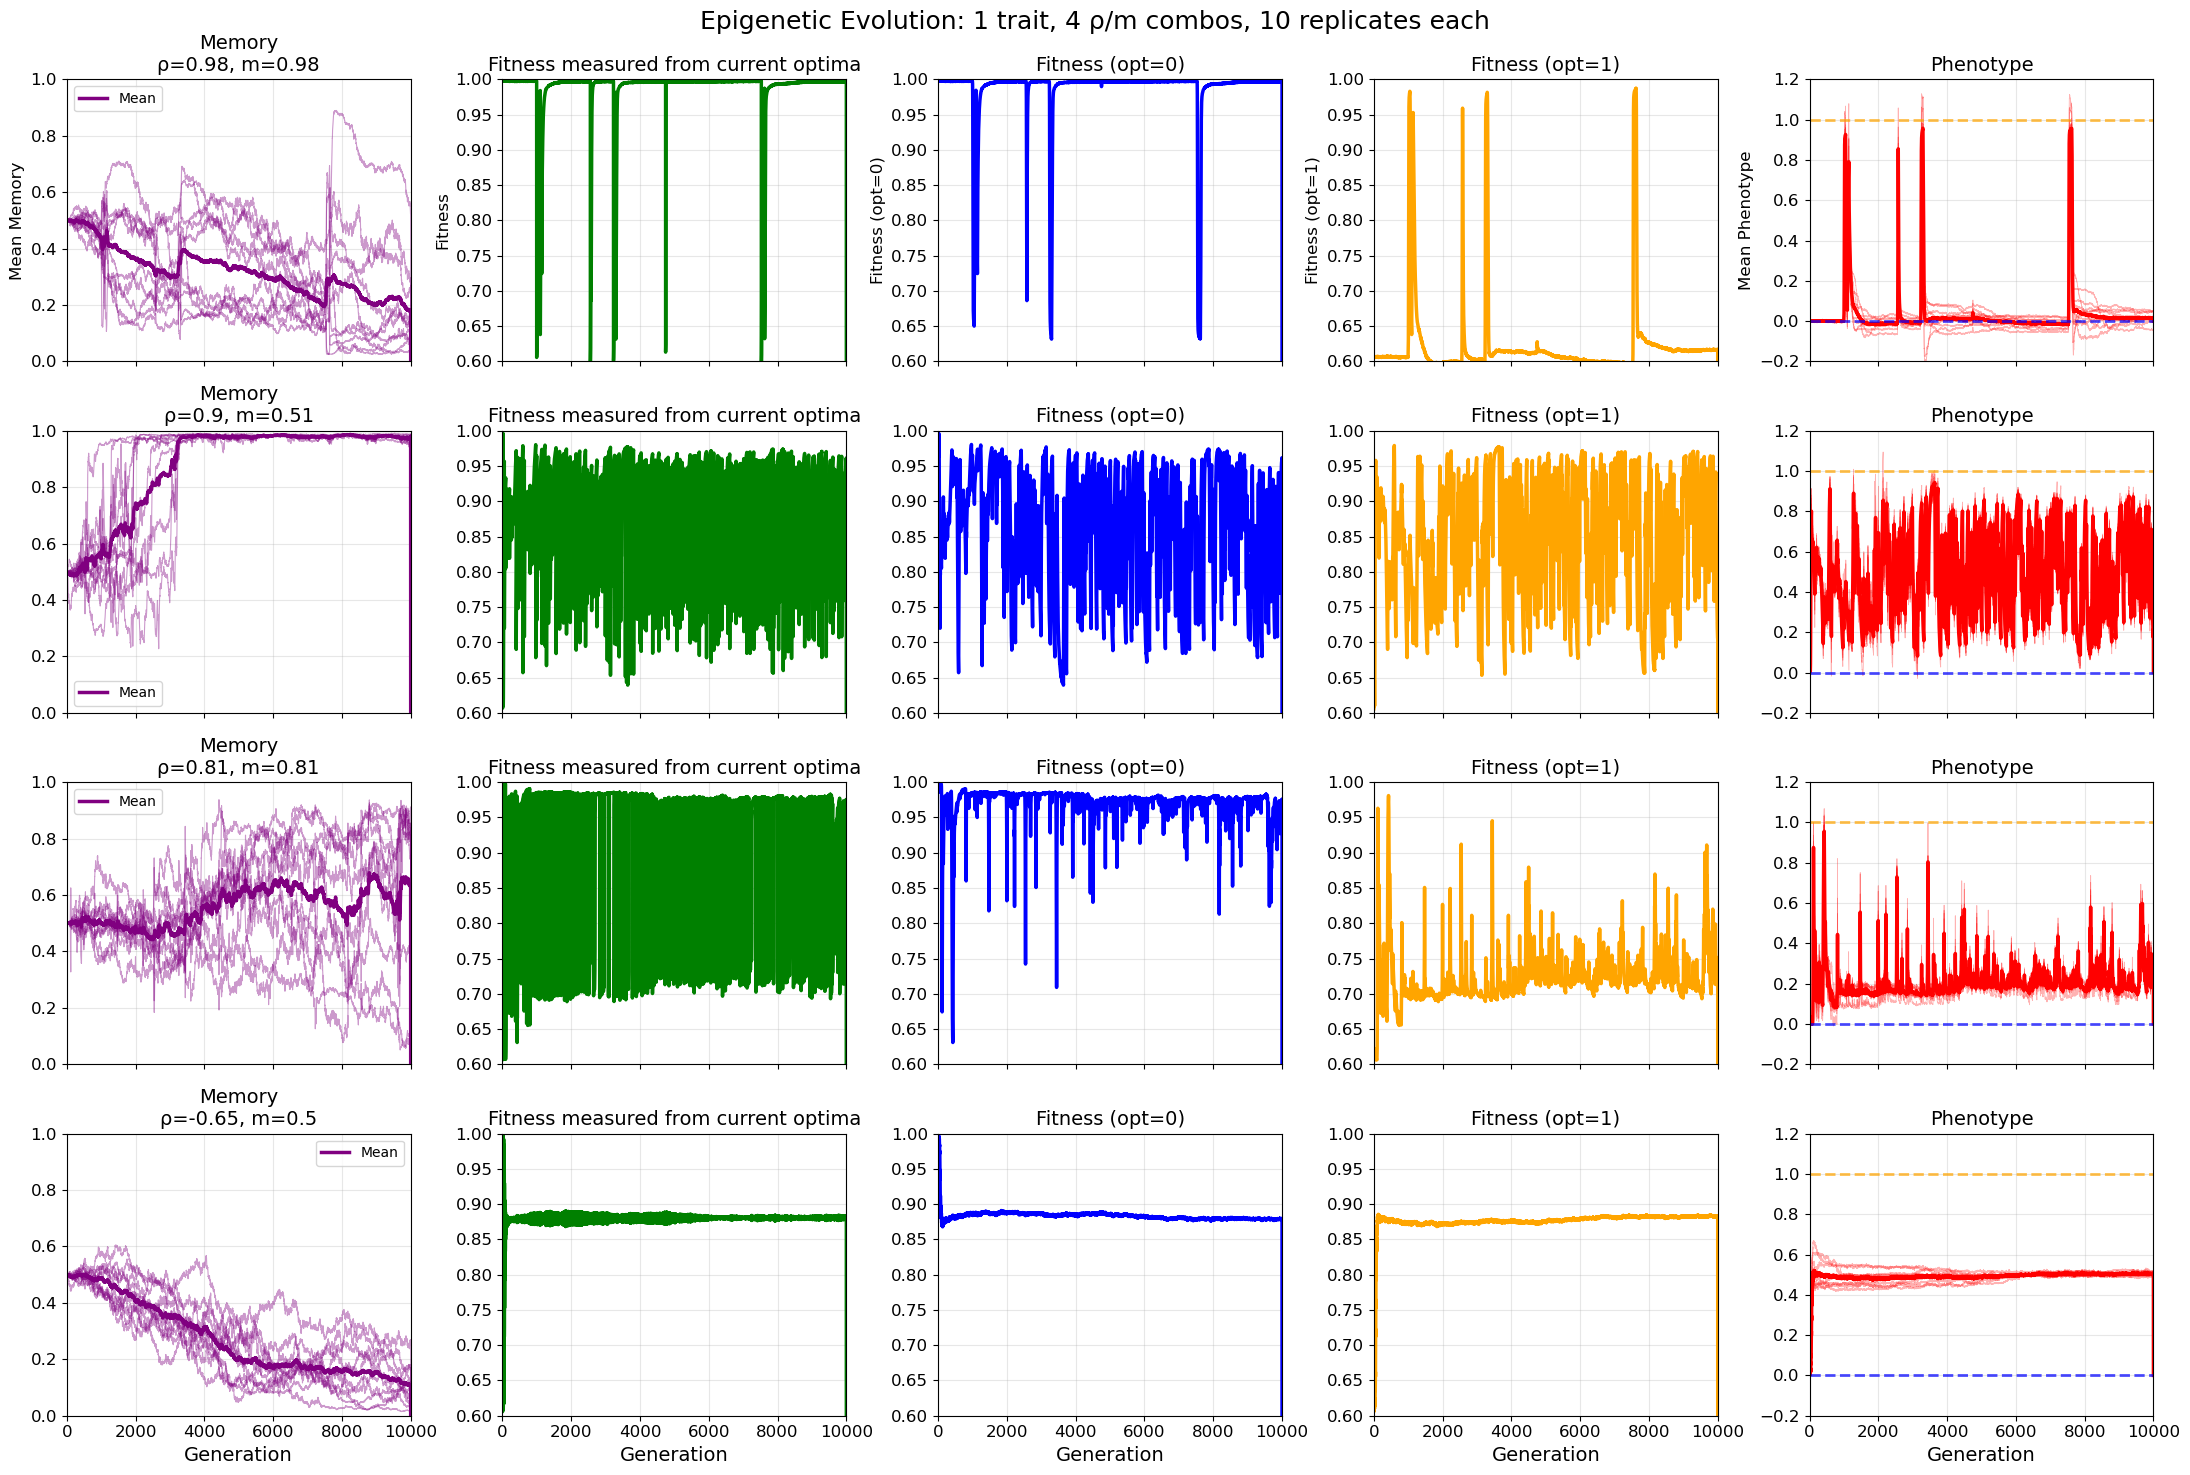

In [13]:
# Your existing params
rho_vals = [rho_val_0, rho_val_1, rho_val_2, rho_val_3]
m_vals = [m_val_0, m_val_1, m_val_2, m_val_3]
nof_dims = 1

fig, ax = plt.subplots(4, 5, figsize=(22, 15), sharex='all')  # Changed to 5 columns

gens = np.arange(1, maxgen + 1)
xlim = 10000
optimum_0 = 0
optimum_1 = 1
n_replicates = 10  # replicates per combo
n_combos = 4

# Assuming phenotype shape is (1, 40, maxgen) or (40, maxgen) for 1 trait
# If (40, maxgen), use phenotype[row_idx, :]
# If (1, 40, maxgen), use phenotype[0, row_idx, :]

for combo in range(n_combos):
    # Calculate row indices for this combo's 10 replicates
    start_row = combo * n_replicates
    end_row = start_row + n_replicates
    
    # Column 0: Memory - plot all 10 replicates
    for rep in range(n_replicates):
        row_idx = start_row + rep
        ax[combo, 0].plot(gens, meanmemory_p[row_idx, :], 
                         color='purple', linewidth=0.8, alpha=0.4)
    # Add mean line
    ax[combo, 0].plot(gens, meanmemory_p[start_row:end_row, :].mean(axis=0), 
                     color='purple', linewidth=2.5, label='Mean')
    ax[combo, 0].set_title(f'Memory\nρ={rho_vals[combo]}, m={m_vals[combo]}', fontsize=14)
    ax[combo, 0].set_ylim(0, 1)
    ax[combo, 0].legend(fontsize=10)
    
    # Column 1: Original Fitness - mean only
    ax[combo, 1].plot(gens, fitness[start_row:end_row, :].mean(axis=0), 
                     color='green', linewidth=2.5, label='Mean')
    ax[combo, 1].set_title('Fitness measured from current optima', fontsize=14)
    ax[combo, 1].set_ylim(0.6, 1)
    #ax[combo, 1].legend(fontsize=10)
    
    # Column 2: Fitness from optimum=0 - mean only
    ax[combo, 2].plot(gens, fitness0[start_row:end_row, :].mean(axis=0), 
                     color='blue', linewidth=2.5, label='Mean')
    ax[combo, 2].set_title(f'Fitness (opt={optimum_0})', fontsize=14)
    ax[combo, 2].set_ylim(0.6, 1)
   # ax[combo, 2].legend(fontsize=10)
    
    # Column 3: Fitness from optimum=1 - mean only
    ax[combo, 3].plot(gens, fitness1[start_row:end_row, :].mean(axis=0), 
                     color='orange', linewidth=2.5, label='Mean')
    ax[combo, 3].set_title(f'Fitness (opt={optimum_1})', fontsize=14)
    ax[combo, 3].set_ylim(0.6, 1)
    #ax[combo, 3].legend(fontsize=10)
    
    # Column 4: Phenotype - plot all 10 replicates WITH optimum lines
    for rep in range(n_replicates):
        row_idx = start_row + rep
        # Adjust indexing based on your phenotype shape:
        # If phenotype is (40, maxgen):
        ax[combo, 4].plot(gens, phenotype[row_idx, :], 
                         color='red', linewidth=0.6, alpha=0.3, label='Replicate' if rep == 0 else "")
        # If phenotype is (1, 40, maxgen), use:
        # ax[combo, 4].plot(gens, phenotype[0, row_idx, :], 
        #                  color='red', linewidth=0.6, alpha=0.3)
    
    # Add mean phenotype line
    ax[combo, 4].plot(gens, phenotype[start_row:end_row, :].mean(axis=0), 
                     color='red', linewidth=2.5, label='Mean')
    
    # Add optimum lines
    ax[combo, 4].axhline(y=optimum_0, color='blue', linestyle='--', linewidth=2, alpha=0.7, label=f'Optimum={optimum_0}')
    ax[combo, 4].axhline(y=optimum_1, color='orange', linestyle='--', linewidth=2, alpha=0.7, label=f'Optimum={optimum_1}')
    
    ax[combo, 4].set_title('Phenotype', fontsize=14)
    ax[combo, 4].set_ylim(-0.2, 1.2)  # Adjust as needed
    #ax[combo, 4].legend(fontsize=10)
    
    # Set x-limits
    for col in range(5):
        ax[combo, col].set_xlim(0, xlim)

# Y-labels (only on first row)
ylabels = ['Mean Memory', 'Fitness', 'Fitness (opt=0)', 'Fitness (opt=1)', 'Mean Phenotype']
for col in range(5):
    ax[0, col].set_ylabel(ylabels[col], fontsize=12)

# Formatting
for row in range(4):
    for col in range(5):
        ax[row, col].tick_params(axis='both', labelsize=12)
        ax[row, col].grid(True, alpha=0.3)

# X-labels only on bottom row
for col in range(5):
    ax[3, col].set_xlabel('Generation', fontsize=14)

fig.suptitle(f'Epigenetic Evolution: {nof_dims} trait, 4 ρ/m combos, 10 replicates each', fontsize=18)
plt.tight_layout()
plt.show()

### Two Traits

In [14]:
onlygen = False

# Number of dimensions (can be 1 or more)
nof_dimensions = 2

# get the cube dimensions
dims = get_cube_dims(nof_dimensions)

#create the cube
N = create_cube(popsize, dims=dims, nof_dimensions=nof_dimensions, epsilon=epsilon, initial_memory=initial_memory)

print(N.shape)


### Define seed_array
seed_array = np.linspace(0, 10000, num=4*n_reps, dtype=int)

if __name__ == '__main__':
    
    # Create all combinations of sigma_mut and sigma_alpha
    param_grid = [
        (scenario, seed, popsize, maxgen, dims, N, mutsize, mutrate, epsilon, nof_dimensions, False) #only genetics can either be True or false
        for scenario, seed in zip(Env_stoch, seed_array) #where each row corresponds to one scenario
    ]

    num_cpus = 13
    
    with concurrent.futures.ProcessPoolExecutor(num_cpus) as executor: 
        results_array_stoch2 = list(executor.map(run_simulation, param_grid))

(5000, 8)
Using seed: 0Using seed: 256
Using seed: 512

Using seed: 769Using seed: 1025
Using seed: 1282Gen 0: Running EPIGENETIC mode
Using seed: 1538


Gen 0: Running EPIGENETIC modeUsing seed: 1794Gen 0: Running EPIGENETIC modeUsing seed: 2051
Gen 0: Running EPIGENETIC mode


Gen 0: Running EPIGENETIC modeUsing seed: 2307


Gen 0: Running EPIGENETIC modeGen 0: Running EPIGENETIC mode
Using seed: 2820
Using seed: 2564Gen 0: Running EPIGENETIC modeGen 0: Running EPIGENETIC mode



Gen 0: Running EPIGENETIC mode
Gen 0: Running EPIGENETIC modeGen 0: Running EPIGENETIC mode

Using seed: 3076
Gen 0: Running EPIGENETIC mode
Using seed: 3333
Gen 0: Running EPIGENETIC mode
Using seed: 3589
Gen 0: Running EPIGENETIC mode
Using seed: 3846
Gen 0: Running EPIGENETIC mode
Using seed: 4102
Gen 0: Running EPIGENETIC mode
Using seed: 4358
Gen 0: Running EPIGENETIC mode
Using seed: 4615
Gen 0: Running EPIGENETIC mode
Using seed: 4871
Using seed: 5128Gen 0: Running EPIGENETIC mode

Gen 0: Running EPIG

In [ ]:
#Collect keys of all the list objects 
keys = list(results_array_stoch2[0].keys())

concatenated_results_epi_stoch_2 = {}


for k in keys:
        concatenated_results_epi_stoch_2[k] = np.vstack([r[k] for r in results_array_stoch2])


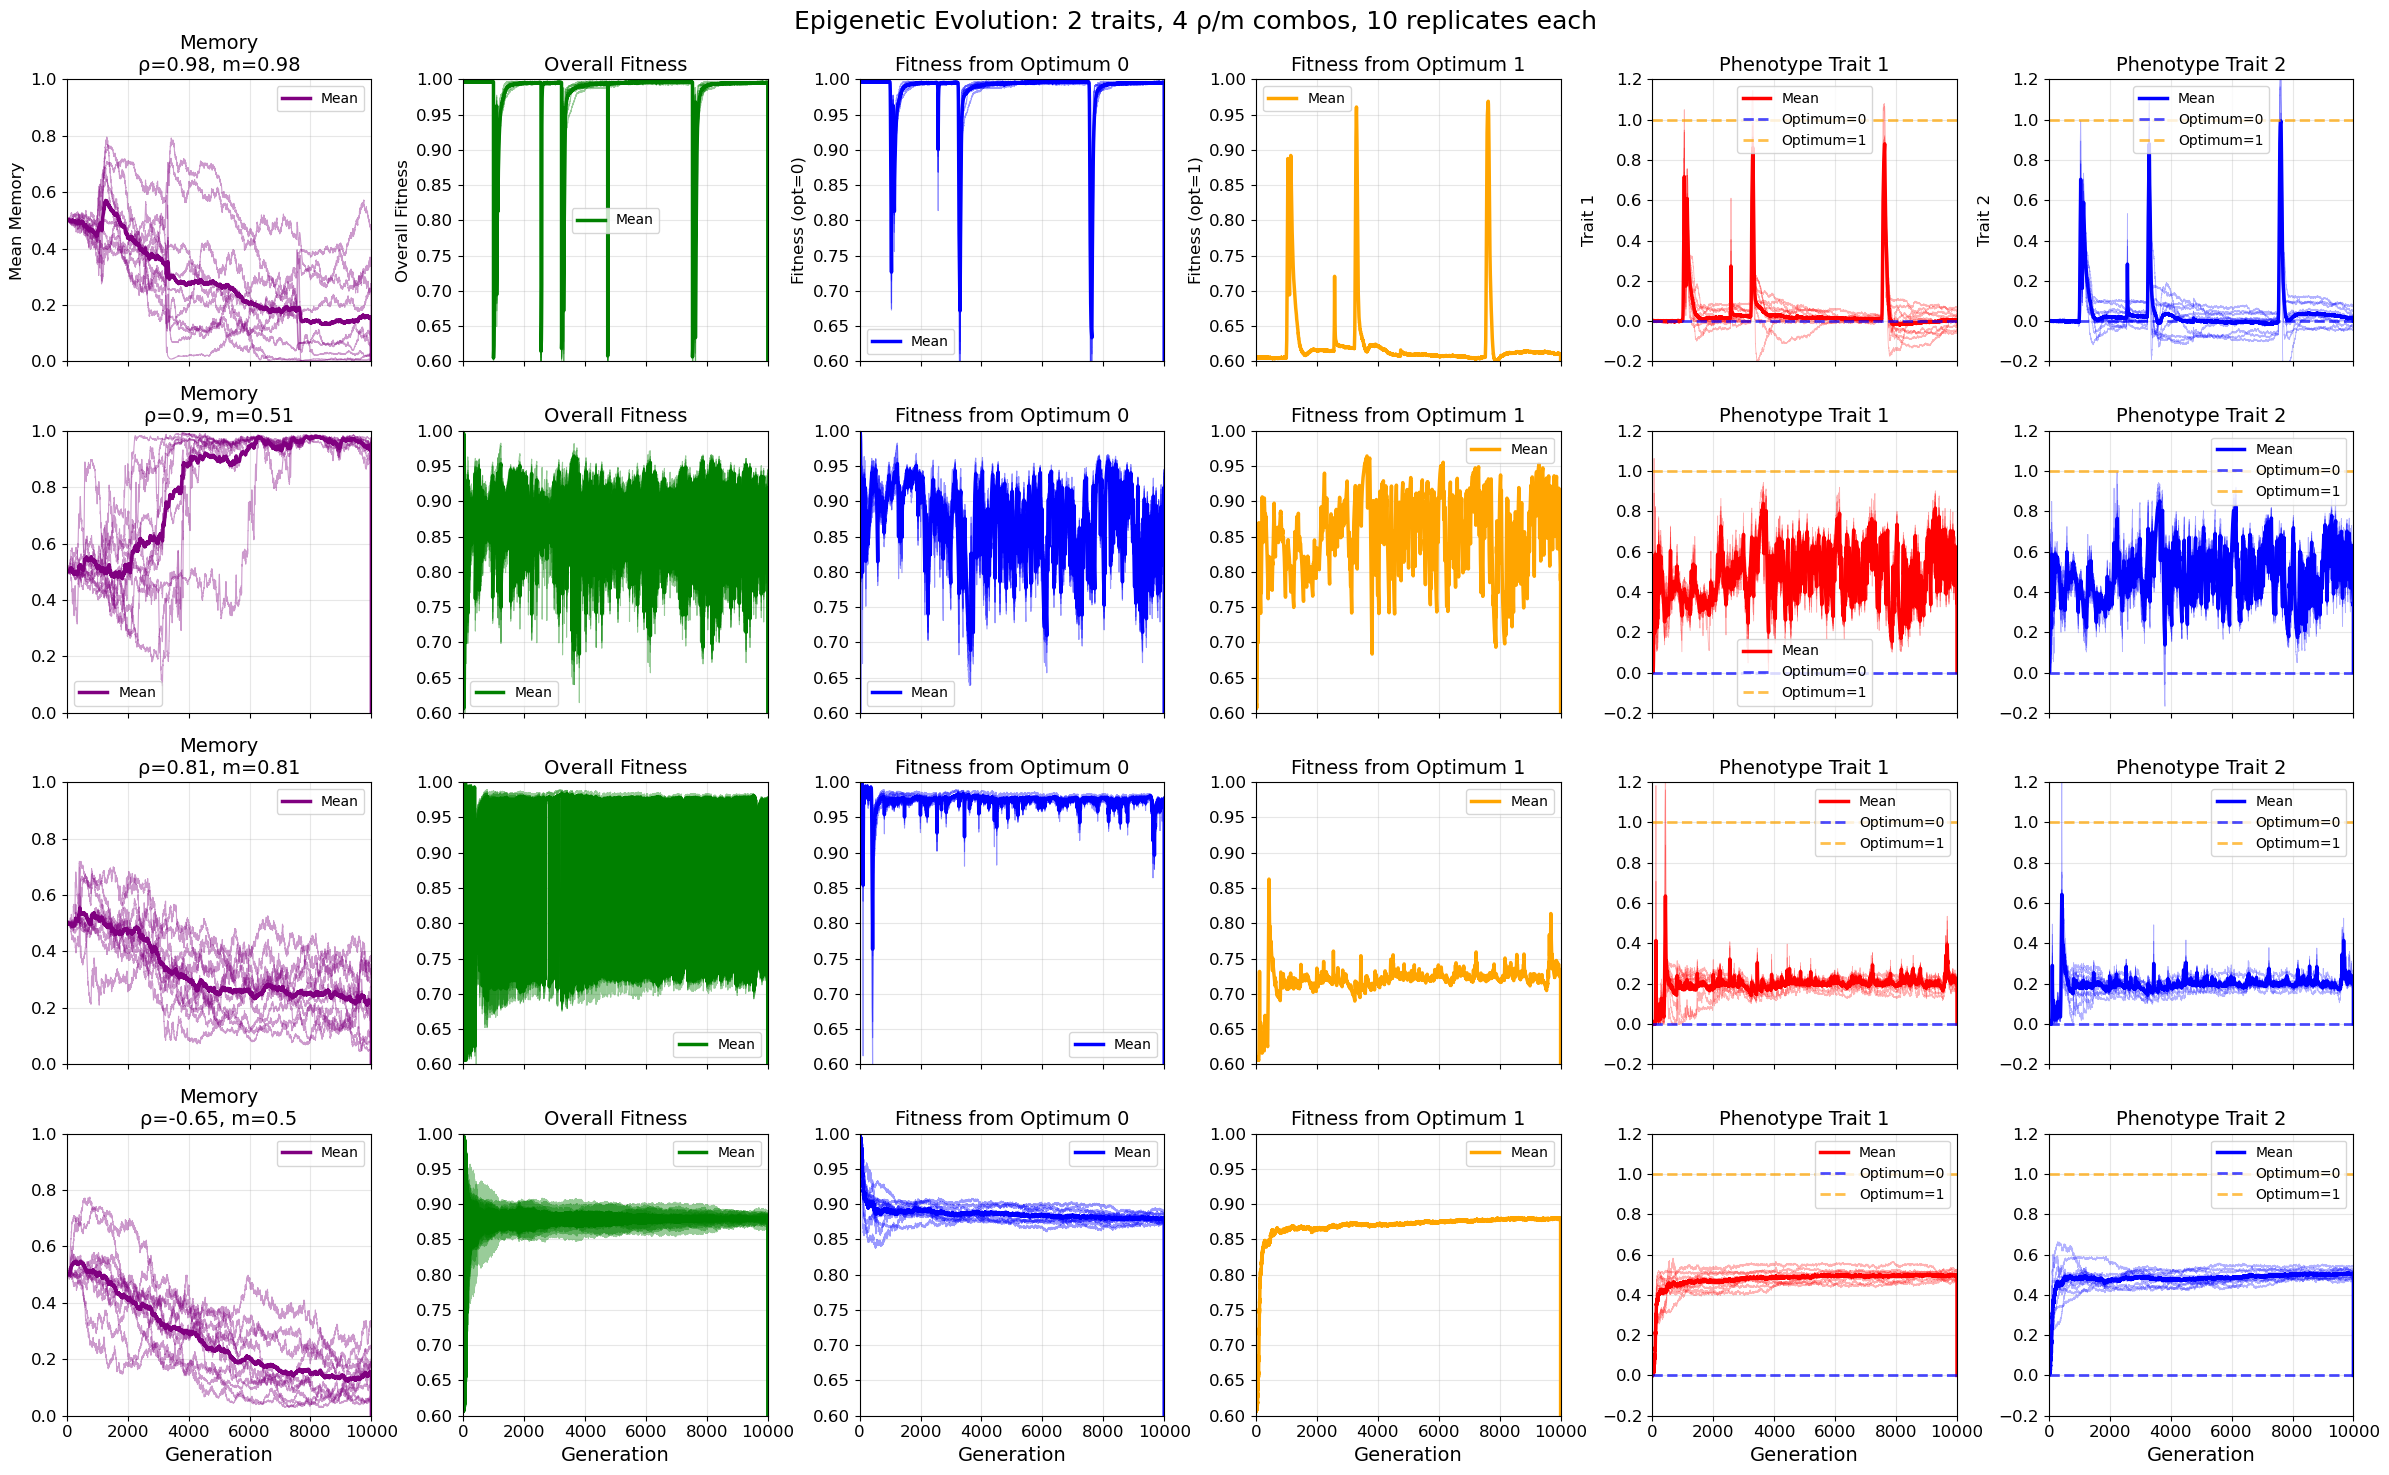

In [16]:
# Your data
meanmemory_p = concatenated_results_epi_stoch_2['meanmemory_p']  # (40, maxgen) - 4 combos × 10 reps
fitness = concatenated_results_epi_stoch_2['meanw']              # (40, maxgen)
fitness0 = concatenated_results_epi_stoch_2['meanw0']            # (40, maxgen) - fitness from opt=0
fitness1 = concatenated_results_epi_stoch_2['meanw1']            # (40, maxgen) - fitness from opt=1
mean_pheno = concatenated_results_epi_stoch_2['mean_pheno']      # (80, maxgen) - 4 combos × 2 traits × 10 reps

rho_vals = [rho_val_0, rho_val_1, rho_val_2, rho_val_3]
m_vals = [m_val_0, m_val_1, m_val_2, m_val_3]
nof_dims = 2

fig, ax = plt.subplots(4, 6, figsize=(24, 15), sharex='all')  # 6 columns

gens = np.arange(1, maxgen + 1)
xlim = 10000
n_replicates = 10  # replicates per combo per trait
n_combos = 4
optimum_0 = 0
optimum_1 = 1

for combo in range(n_combos):
    # For phenotype: 80 rows structured as combo×trait×rep
    pheno_trait1_start = combo * 20
    pheno_trait1_end = pheno_trait1_start + n_replicates
    
    pheno_trait2_start = combo * 20 + n_replicates
    pheno_trait2_end = pheno_trait2_start + n_replicates
    
    # Row indices for this combo's 10 replicates (for memory/fitness)
    start_row = combo * n_replicates
    end_row = start_row + n_replicates
    
    # Column 0: Memory - plot all 10 replicates
    for rep in range(n_replicates):
        row_idx = start_row + rep
        ax[combo, 0].plot(gens, meanmemory_p[row_idx, :], 
                         color='purple', linewidth=0.8, alpha=0.4)
    ax[combo, 0].plot(gens, meanmemory_p[start_row:end_row, :].mean(axis=0), 
                     color='purple', linewidth=2.5, label='Mean')
    ax[combo, 0].set_title(f'Memory\nρ={rho_vals[combo]}, m={m_vals[combo]}', fontsize=14)
    ax[combo, 0].set_ylim(0, 1)
    ax[combo, 0].legend(fontsize=10)
    
    # Column 1: Original Fitness - plot all 10 replicates
    for rep in range(n_replicates):
        row_idx = start_row + rep
        ax[combo, 1].plot(gens, fitness[row_idx, :], 
                         color='green', linewidth=0.8, alpha=0.4)
    ax[combo, 1].plot(gens, fitness[start_row:end_row, :].mean(axis=0), 
                     color='green', linewidth=2.5, label='Mean')
    ax[combo, 1].set_title('Overall Fitness', fontsize=14)
    ax[combo, 1].set_ylim(0.6, 1)
    ax[combo, 1].legend(fontsize=10)
    
    # Column 2: Fitness from optimum 0 - plot all 10 replicates
    for rep in range(n_replicates):
        row_idx = start_row + rep
        ax[combo, 2].plot(gens, fitness0[row_idx, :], 
                         color='blue', linewidth=0.8, alpha=0.4)
    ax[combo, 2].plot(gens, fitness0[start_row:end_row, :].mean(axis=0), 
                     color='blue', linewidth=2.5, label='Mean')
    ax[combo, 2].set_title('Fitness from Optimum 0', fontsize=14)
    ax[combo, 2].set_ylim(0.6, 1)
    ax[combo, 2].legend(fontsize=10)
    
    # Column 3: Fitness from optimum 1 - plot all 10 replicates
    #for rep in range(n_replicates):
    #    row_idx = start_row + rep
    #    ax[combo, 3].plot(gens, fitness1[row_idx, :], 
    #                     color='orange', linewidth=0.8, alpha=0.4)
    ax[combo, 3].plot(gens, fitness1[start_row:end_row, :].mean(axis=0), 
                     color='orange', linewidth=2.5, label='Mean')
    ax[combo, 3].set_title('Fitness from Optimum 1', fontsize=14)
    ax[combo, 3].set_ylim(0.6, 1)
    ax[combo, 3].legend(fontsize=10)
    
    # Column 4: Phenotype Trait 1 - plot all 10 replicates with optimum line
    for rep in range(n_replicates):
        row_idx = pheno_trait1_start + rep
        ax[combo, 4].plot(gens, mean_pheno[row_idx, :], 
                         color='red', linewidth=0.6, alpha=0.3)
    ax[combo, 4].plot(gens, mean_pheno[pheno_trait1_start:pheno_trait1_end, :].mean(axis=0), 
                     color='red', linewidth=2.5, label='Mean')
    ax[combo, 4].axhline(y=optimum_0, color='blue', linestyle='--', linewidth=2, alpha=0.7, label=f'Optimum={optimum_0}')
    ax[combo, 4].axhline(y=optimum_1, color='orange', linestyle='--', linewidth=2, alpha=0.7, label=f'Optimum={optimum_1}')
    ax[combo, 4].set_title('Phenotype Trait 1', fontsize=14)
    ax[combo, 4].set_ylim(-0.2, 1.2)
    ax[combo, 4].legend(fontsize=10)
    
    # Column 5: Phenotype Trait 2 - plot all 10 replicates with optimum line
    for rep in range(n_replicates):
        row_idx = pheno_trait2_start + rep
        ax[combo, 5].plot(gens, mean_pheno[row_idx, :], 
                        color='blue', linewidth=0.6, alpha=0.3)
    ax[combo, 5].plot(gens, mean_pheno[pheno_trait2_start:pheno_trait2_end, :].mean(axis=0), 
                     color='blue', linewidth=2.5, label='Mean')
    ax[combo, 5].axhline(y=optimum_0, color='blue', linestyle='--', linewidth=2, alpha=0.7, label=f'Optimum={optimum_0}')
    ax[combo, 5].axhline(y=optimum_1, color='orange', linestyle='--', linewidth=2, alpha=0.7, label=f'Optimum={optimum_1}')
    ax[combo, 5].set_title('Phenotype Trait 2', fontsize=14)
    ax[combo, 5].set_ylim(-0.2, 1.2)
    ax[combo, 5].legend(fontsize=10)
    
    # Set x-limits
    for col in range(6):
        ax[combo, col].set_xlim(0, xlim)

# Y-labels (only on first row)
ylabels = ['Mean Memory', 'Overall Fitness', 'Fitness (opt=0)', 'Fitness (opt=1)', 'Trait 1', 'Trait 2']
for col in range(6):
    ax[0, col].set_ylabel(ylabels[col], fontsize=12)

# Formatting
for row in range(4):
    for col in range(6):
        ax[row, col].tick_params(axis='both', labelsize=12)
        ax[row, col].grid(True, alpha=0.3)

# X-labels only on bottom row
for col in range(6):
    ax[3, col].set_xlabel('Generation', fontsize=14)

fig.suptitle(f'Epigenetic Evolution: {nof_dims} traits, 4 ρ/m combos, 10 replicates each', fontsize=18)
plt.tight_layout()
plt.show()

### Traits 10

In [ ]:
onlygen = False

maxgen = 50000 

# Number of dimensions (can be 1 or more)
nof_dimensions = 10

# get the cube dimensions
dims = get_cube_dims(nof_dimensions)

#create the cube
N = create_cube(popsize, dims=dims, nof_dimensions=nof_dimensions, epsilon=epsilon, initial_memory=initial_memory)

print(N.shape)


### Define seed_array
seed_array = np.linspace(0, 10000, num=4*n_reps, dtype=int)

if __name__ == '__main__':
    
    # Create all combinations of sigma_mut and sigma_alpha
    param_grid = [
        (scenario, seed, popsize, maxgen, dims, N, mutsize, mutrate, epsilon, nof_dimensions, False) #only genetics can either be True or false
        for scenario, seed in zip(Env_stoch, seed_array) #where each row corresponds to one scenario
    ]

    num_cpus = 13
    
    with concurrent.futures.ProcessPoolExecutor(num_cpus) as executor: 
        results_array_stoch10 = list(executor.map(run_simulation, param_grid))

(5000, 32)
Using seed: 0
Using seed: 256
Using seed: 512
Gen 0: Running EPIGENETIC mode
Using seed: 769
Gen 0: Running EPIGENETIC modeUsing seed: 1025
Gen 0: Running EPIGENETIC mode

Gen 0: Running EPIGENETIC modeUsing seed: 1282

Gen 0: Running EPIGENETIC modeUsing seed: 1538

Using seed: 1794
Gen 0: Running EPIGENETIC mode
Using seed: 2051
Gen 0: Running EPIGENETIC mode
Gen 0: Running EPIGENETIC mode
Gen 0: Running EPIGENETIC mode
Using seed: 2307
Using seed: 2564
Using seed: 2820
Gen 0: Running EPIGENETIC mode
Gen 0: Running EPIGENETIC mode
Using seed: 3076
Gen 0: Running EPIGENETIC mode
Gen 0: Running EPIGENETIC mode
Using seed: 3333
Gen 0: Running EPIGENETIC mode
Using seed: 3589
Gen 0: Running EPIGENETIC mode
Using seed: 3846
Gen 0: Running EPIGENETIC mode
Using seed: 4102
Gen 0: Running EPIGENETIC mode
Using seed: 4358
Gen 0: Running EPIGENETIC mode
Using seed: 4615
Gen 0: Running EPIGENETIC mode
Using seed: 4871
Gen 0: Running EPIGENETIC mode
Using seed: 5128
Gen 0: Running EPI

In [13]:
#Collect keys of all the list objects 
keys = list(results_array_stoch10[0].keys())

concatenated_results_epi_stoch_10 = {}


for k in keys:
        concatenated_results_epi_stoch_10[k] = np.vstack([r[k] for r in results_array_stoch10])


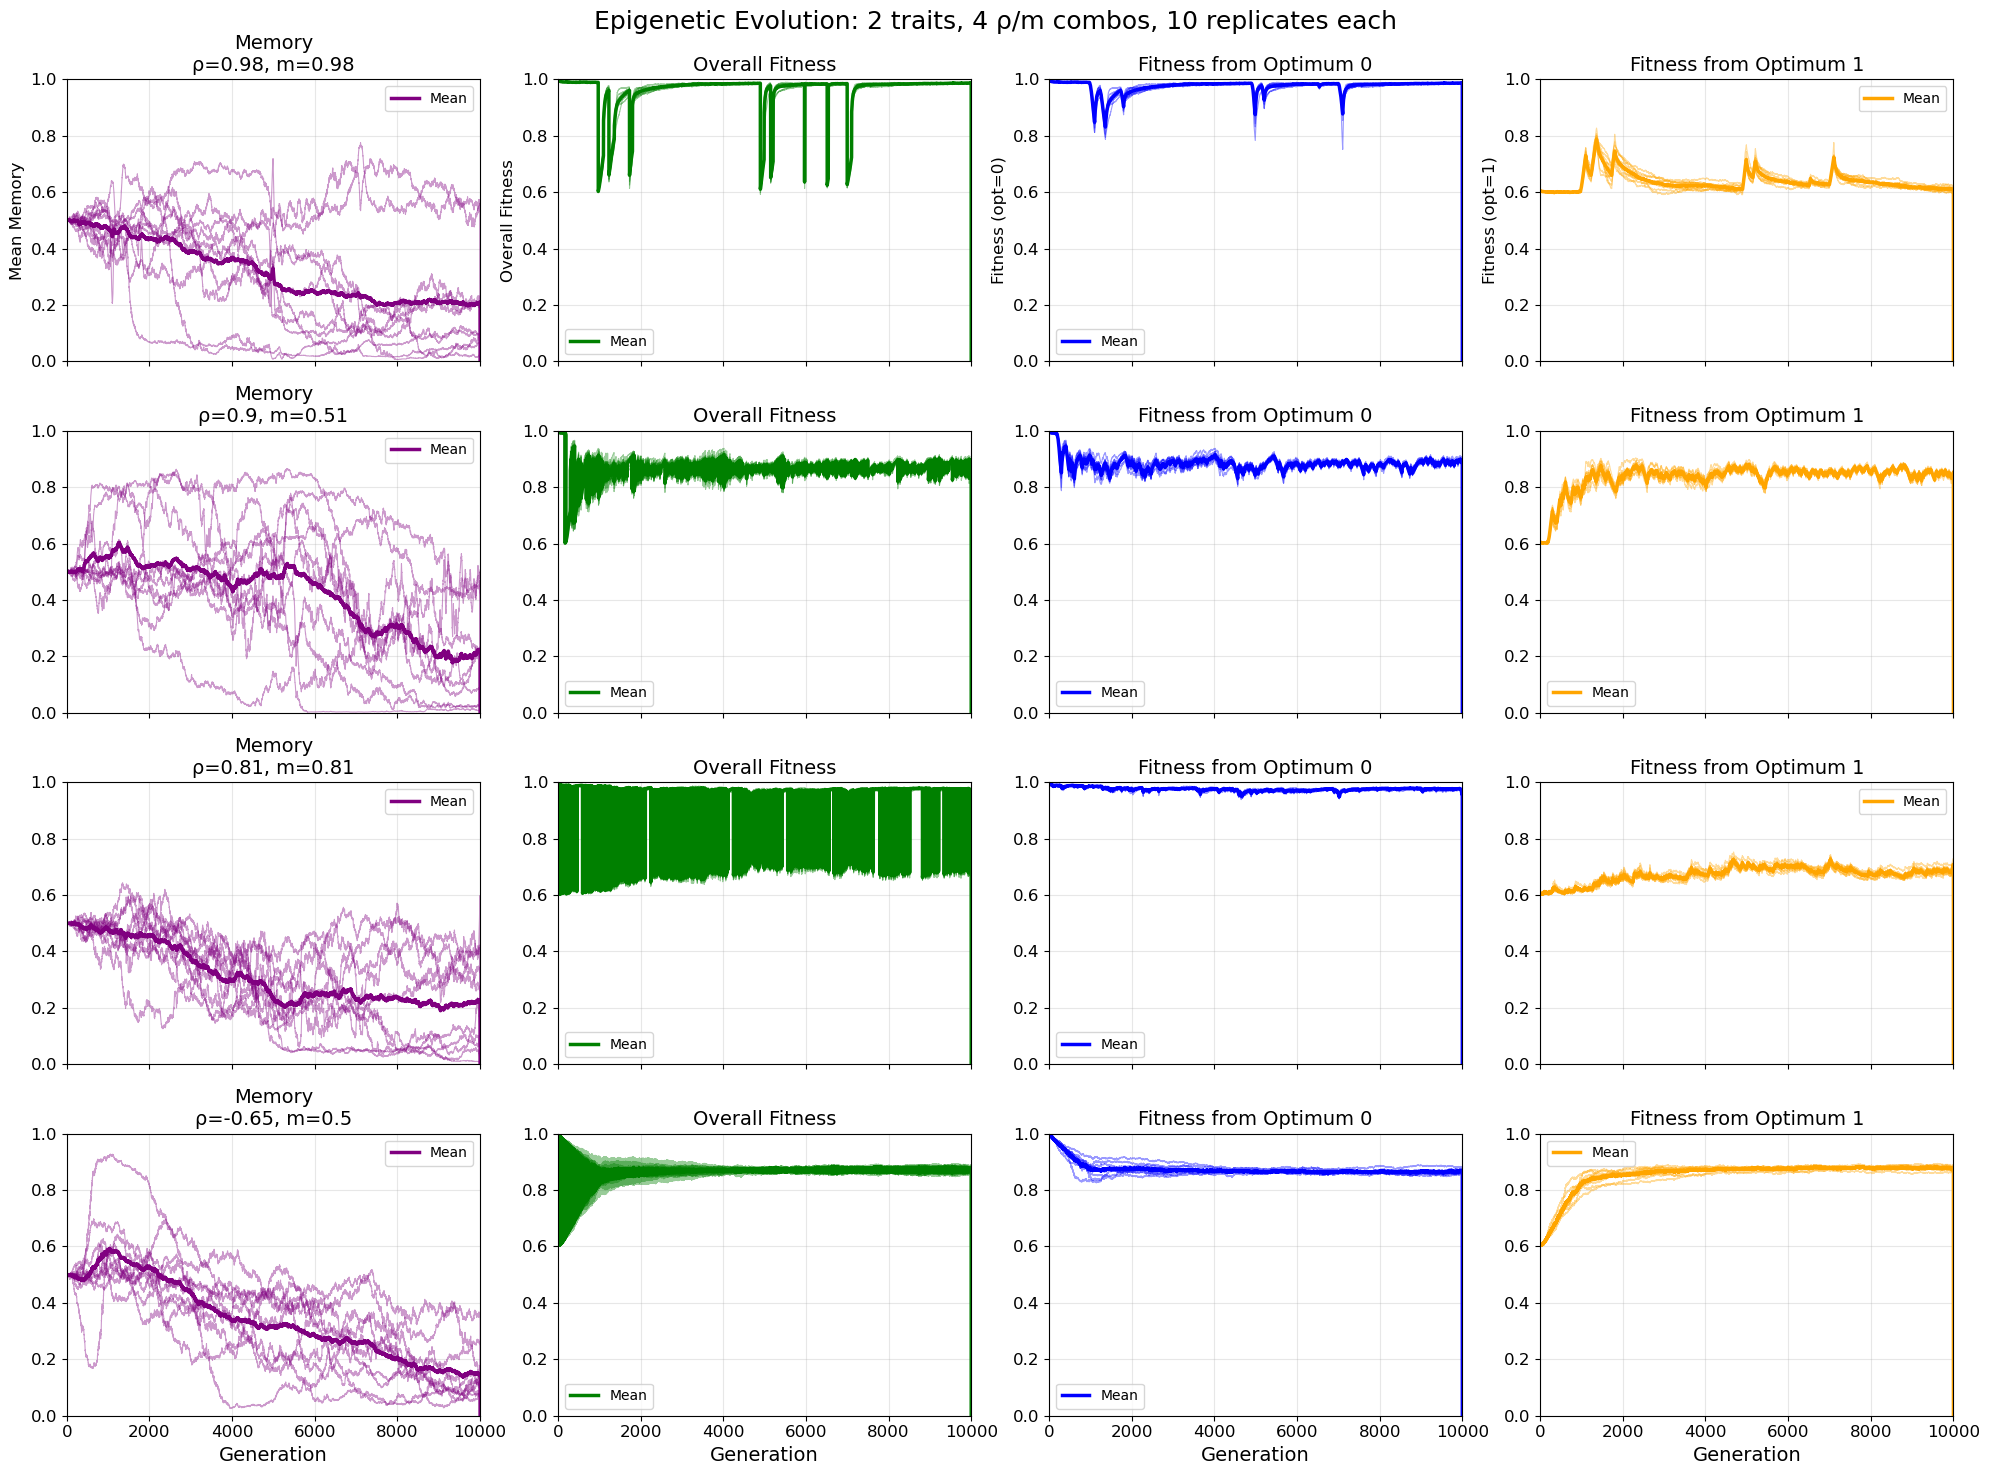

In [14]:
# Your data
meanmemory_p = concatenated_results_epi_stoch_10['meanmemory_p']  # (40, maxgen) - 4 combos × 10 reps
fitness = concatenated_results_epi_stoch_10['meanw']              # (40, maxgen)
fitness0 = concatenated_results_epi_stoch_10['meanw0']            # (40, maxgen) - fitness from opt=0
fitness1 = concatenated_results_epi_stoch_10['meanw1']            # (40, maxgen) - fitness from opt=1

rho_vals = [rho_val_0, rho_val_1, rho_val_2, rho_val_3]
m_vals = [m_val_0, m_val_1, m_val_2, m_val_3]
nof_dims = 2

fig, ax = plt.subplots(4, 4, figsize=(20, 15), sharex='all')

gens = np.arange(1, maxgen + 1)
xlim = 10000
n_replicates = 10  # replicates per combo
n_combos = 4

for combo in range(n_combos):
    # Calculate row indices for this combo's 10 replicates
    start_row = combo * n_replicates
    end_row = start_row + n_replicates
    
    # Column 0: Memory - plot all 10 replicates
    for rep in range(n_replicates):
        row_idx = start_row + rep
        ax[combo, 0].plot(gens, meanmemory_p[row_idx, :], 
                         color='purple', linewidth=0.8, alpha=0.4)
    # Add mean line
    ax[combo, 0].plot(gens, meanmemory_p[start_row:end_row, :].mean(axis=0), 
                     color='purple', linewidth=2.5, label='Mean')
    ax[combo, 0].set_title(f'Memory\nρ={rho_vals[combo]}, m={m_vals[combo]}', fontsize=14)
    ax[combo, 0].set_ylim(0, 1)
    ax[combo, 0].legend(fontsize=10)
    
    # Column 1: Original (overall) Fitness
    for rep in range(n_replicates):
        row_idx = start_row + rep
        ax[combo, 1].plot(gens, fitness[row_idx, :], 
                         color='green', linewidth=0.8, alpha=0.4)
    ax[combo, 1].plot(gens, fitness[start_row:end_row, :].mean(axis=0), 
                     color='green', linewidth=2.5, label='Mean')
    ax[combo, 1].set_title('Overall Fitness', fontsize=14)
    ax[combo, 1].set_ylim(0, 1)
    ax[combo, 1].legend(fontsize=10)
    
    # Column 2: Fitness from optimum 0
    for rep in range(n_replicates):
        row_idx = start_row + rep
        ax[combo, 2].plot(gens, fitness0[row_idx, :], 
                         color='blue', linewidth=0.8, alpha=0.4)
    ax[combo, 2].plot(gens, fitness0[start_row:end_row, :].mean(axis=0), 
                     color='blue', linewidth=2.5, label='Mean')
    ax[combo, 2].set_title('Fitness from Optimum 0', fontsize=14)
    ax[combo, 2].set_ylim(0, 1)
    ax[combo, 2].legend(fontsize=10)
    
    # Column 3: Fitness from optimum 1
    for rep in range(n_replicates):
        row_idx = start_row + rep
        ax[combo, 3].plot(gens, fitness1[row_idx, :], 
                         color='orange', linewidth=0.8, alpha=0.4)
    ax[combo, 3].plot(gens, fitness1[start_row:end_row, :].mean(axis=0), 
                     color='orange', linewidth=2.5, label='Mean')
    ax[combo, 3].set_title('Fitness from Optimum 1', fontsize=14)
    ax[combo, 3].set_ylim(0, 1)
    ax[combo, 3].legend(fontsize=10)
    
    # Set x-limits
    for col in range(4):
        ax[combo, col].set_xlim(0, xlim)

# Y-labels (only on first row)
ylabels = ['Mean Memory', 'Overall Fitness', 'Fitness (opt=0)', 'Fitness (opt=1)']
for col in range(4):
    ax[0, col].set_ylabel(ylabels[col], fontsize=12)

# Formatting
for row in range(4):
    for col in range(4):
        ax[row, col].tick_params(axis='both', labelsize=12)
        ax[row, col].grid(True, alpha=0.3)

# X-labels only on bottom row (row index 3 for 4 rows)
for col in range(4):
    ax[3, col].set_xlabel('Generation', fontsize=14)

fig.suptitle(f'Epigenetic Evolution: {nof_dims} traits, 4 ρ/m combos, 10 replicates each', fontsize=18)
plt.tight_layout()
plt.show()

#### Optionally plot for individual compariosn

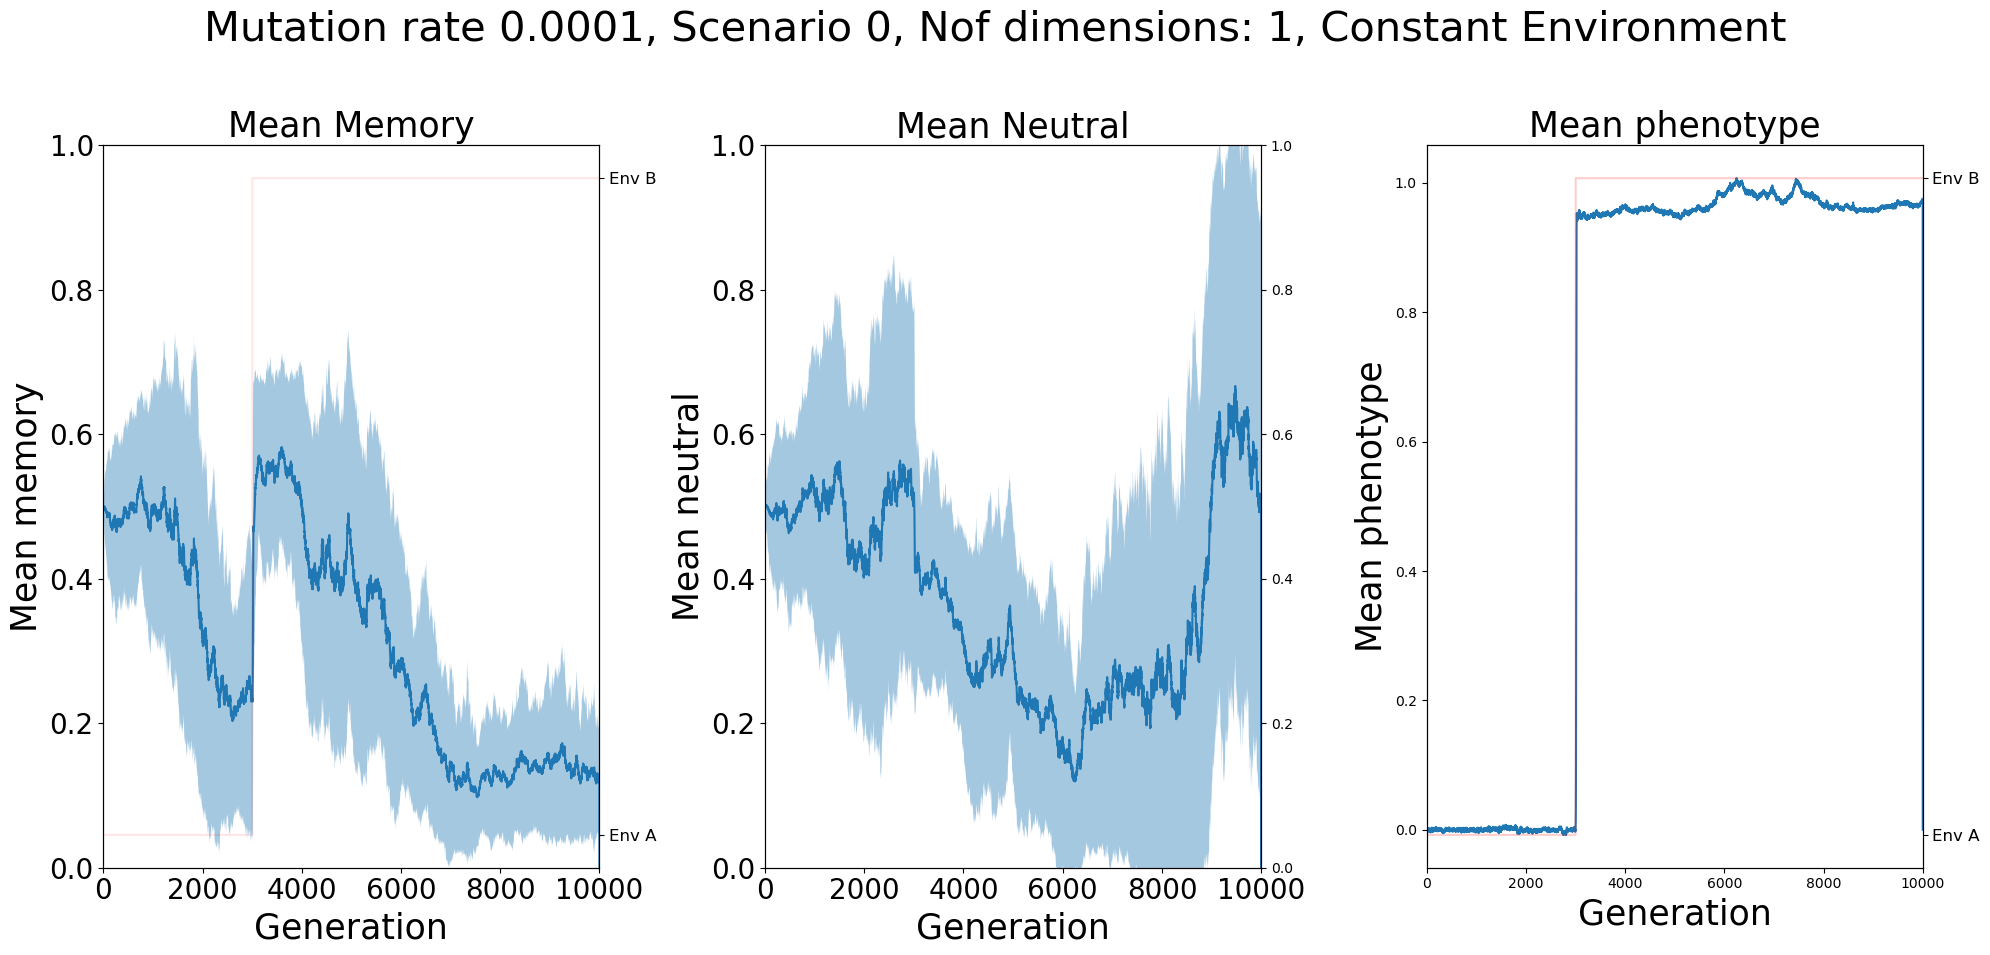

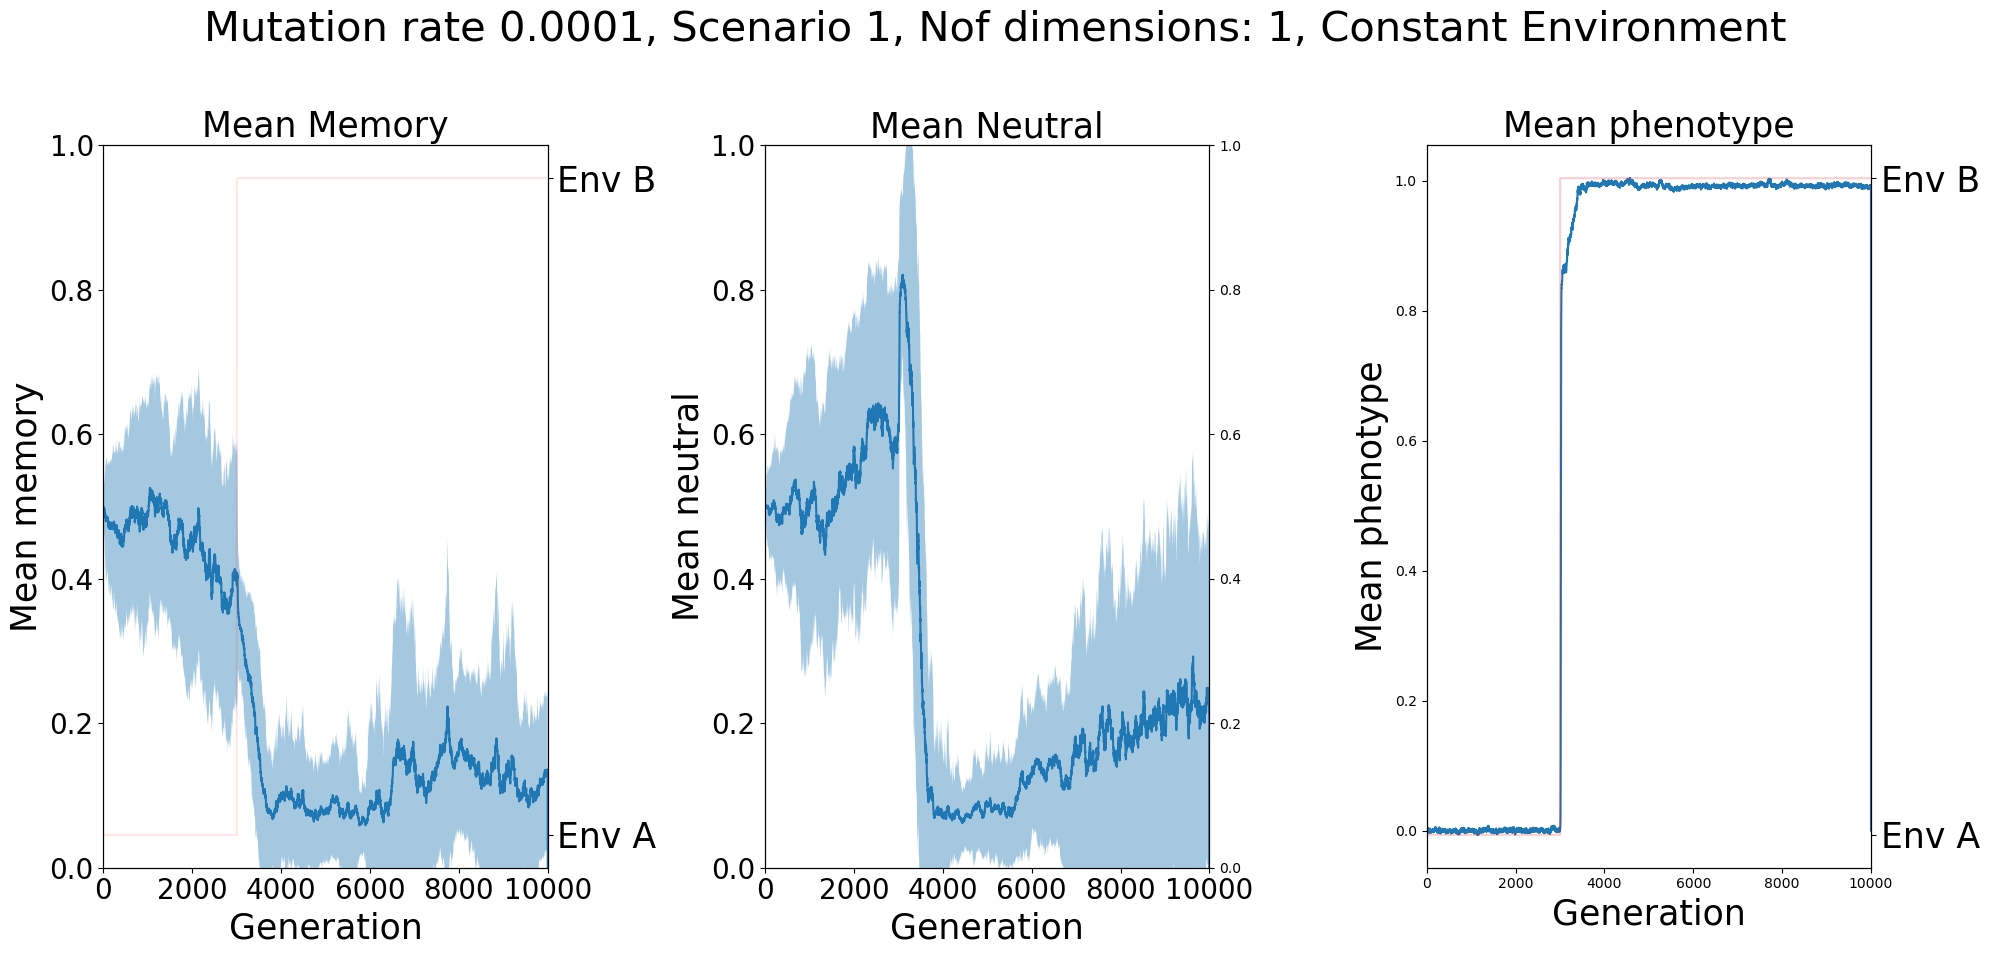

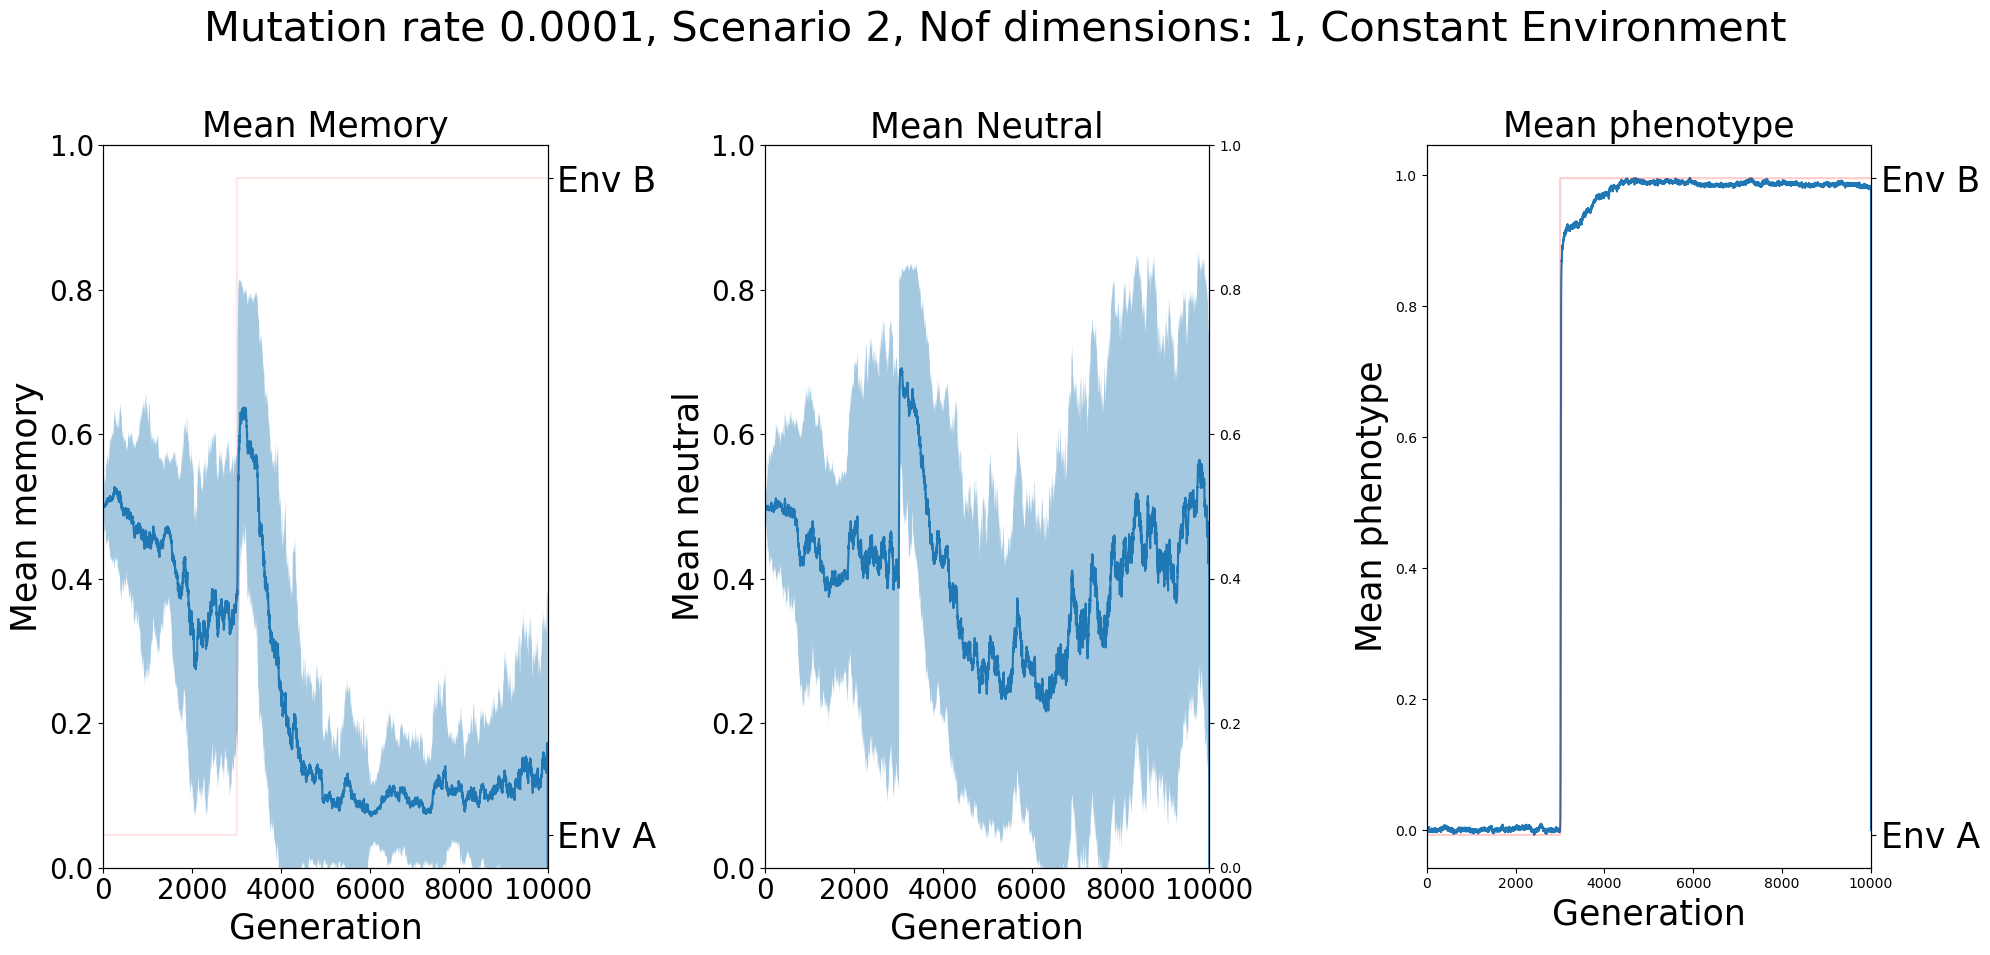

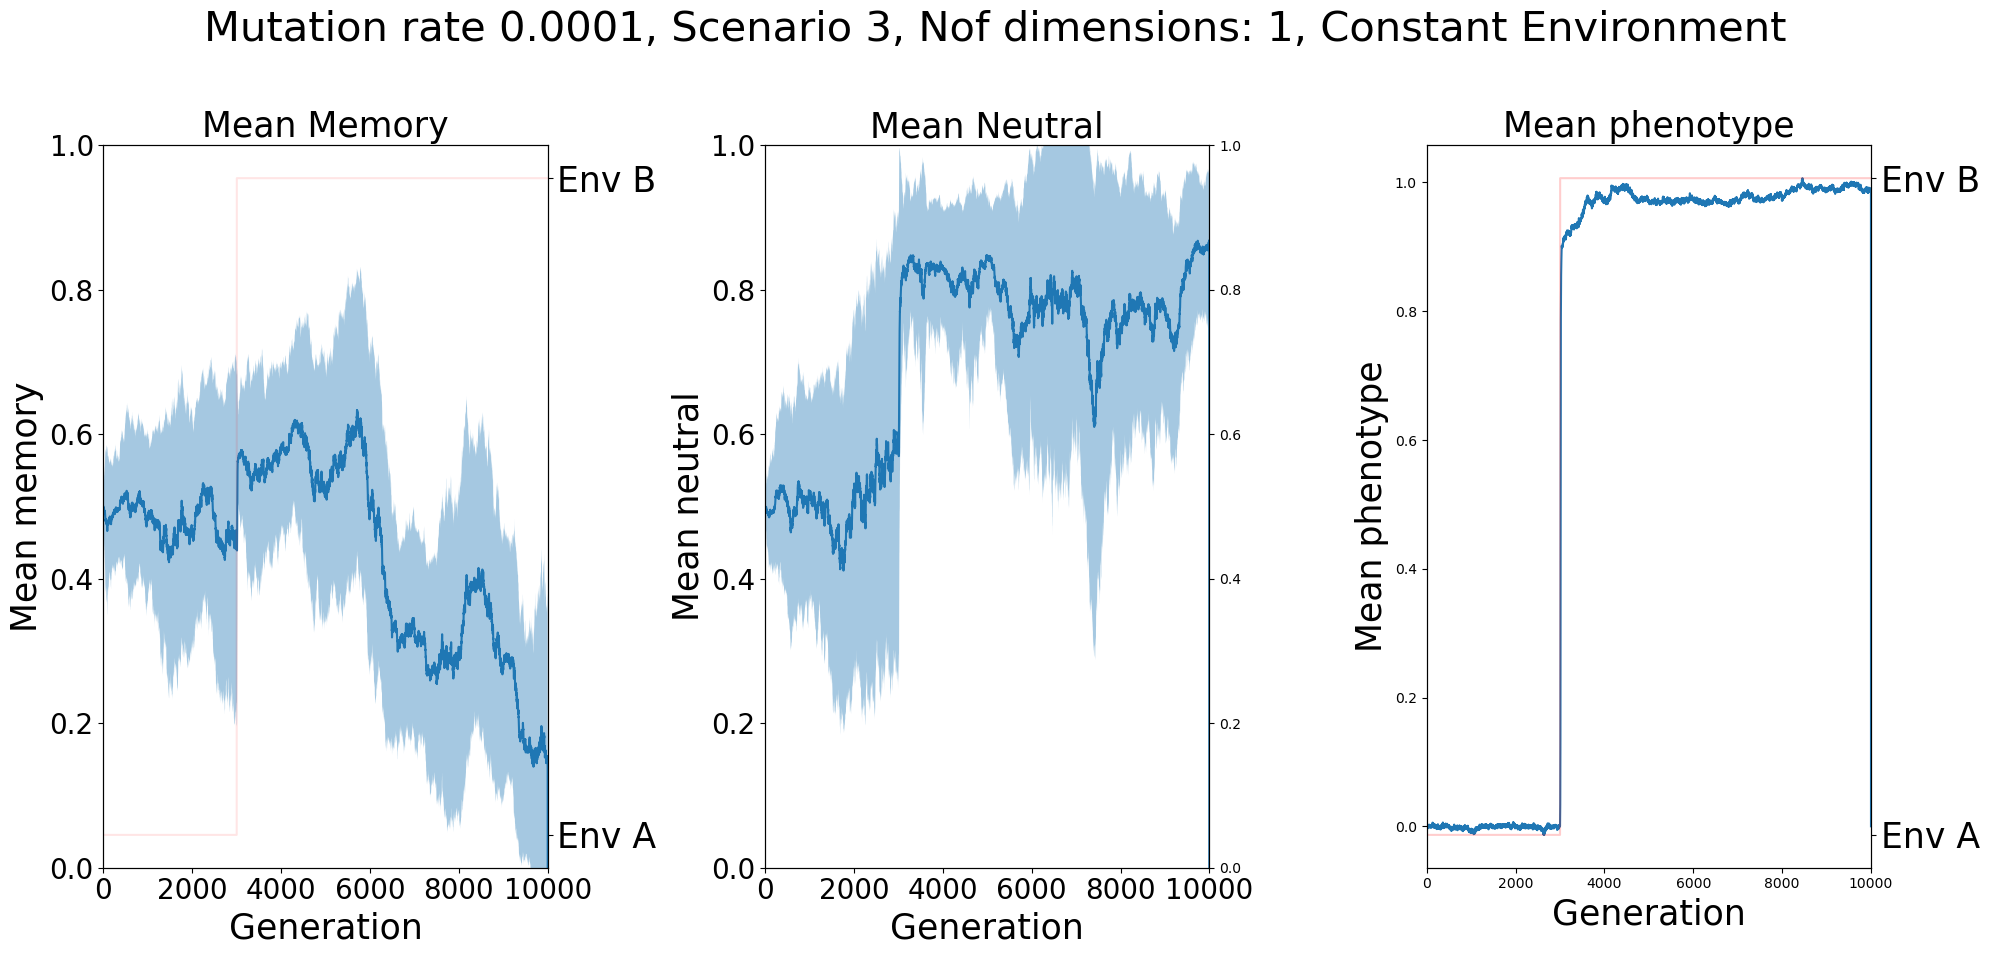

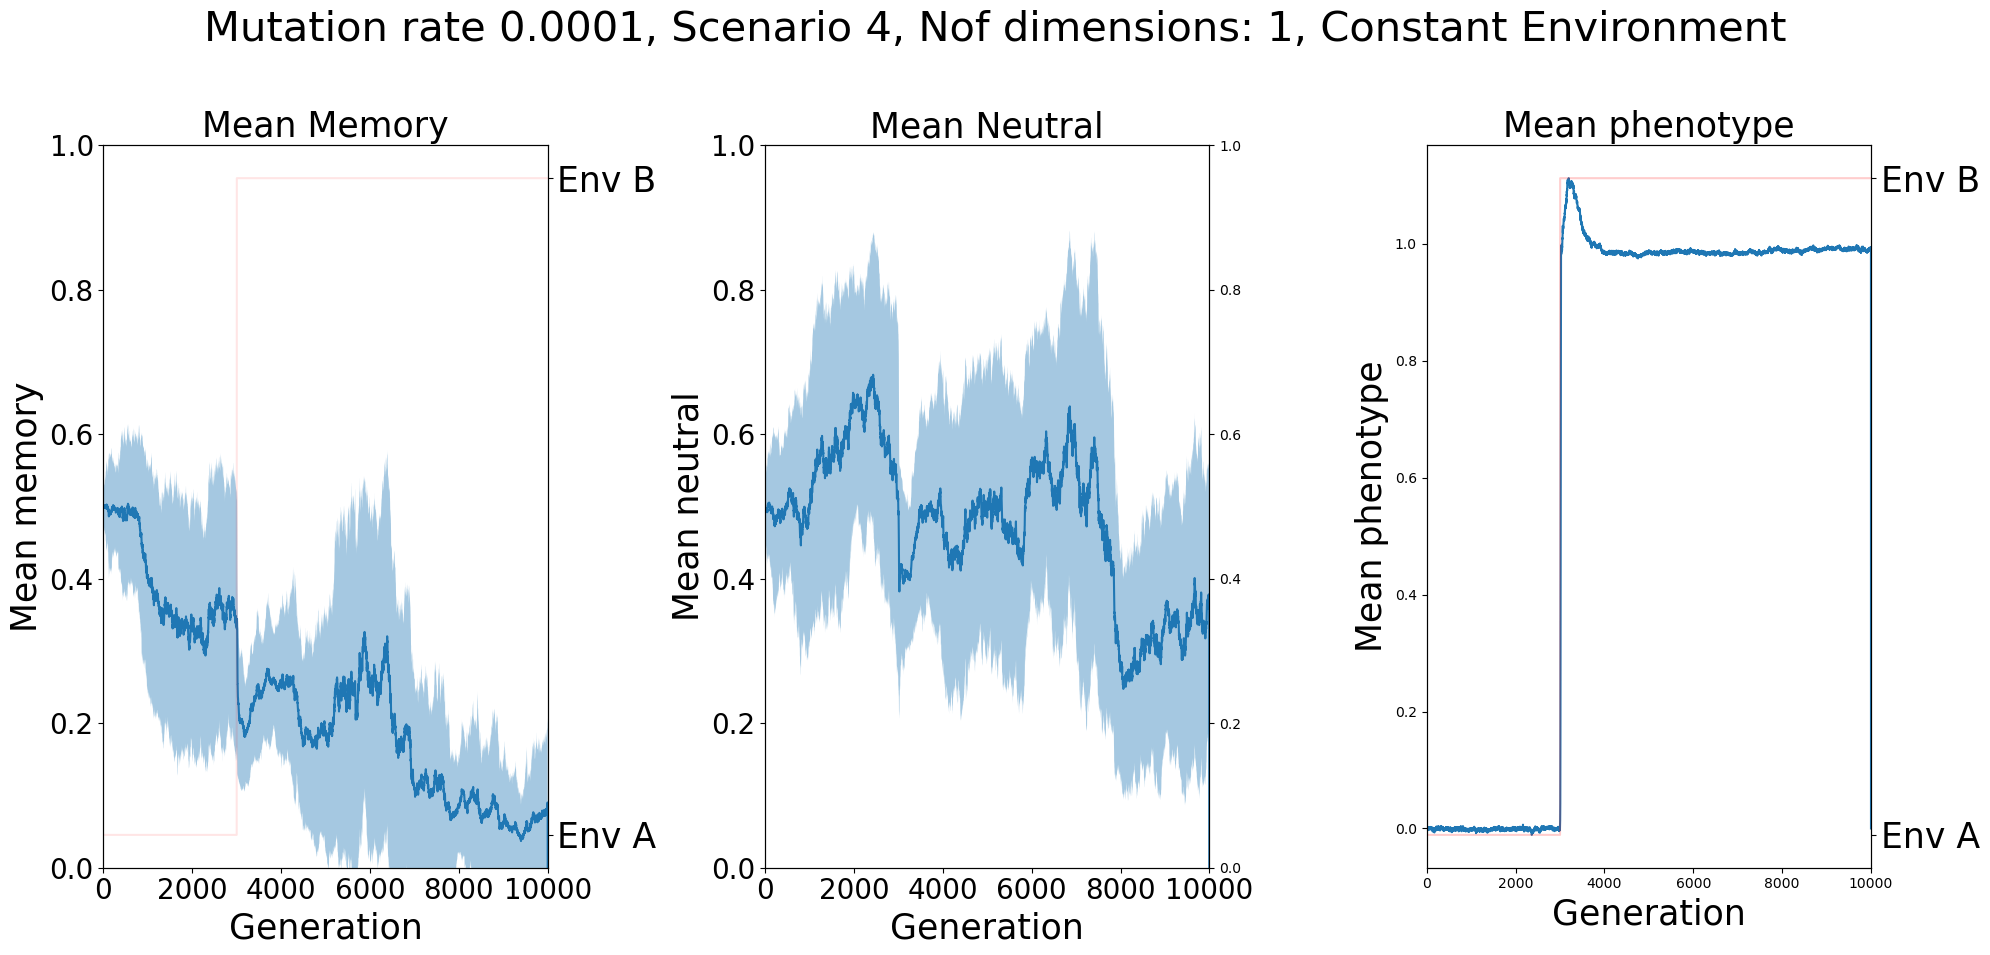

In [46]:

nof_dims=1
start = 0
stop = 5
text_size=12

for i in range(start, stop):
    
    clean_data_env_optima =  Env[i, :]
    
    meanmemory_p = concatenated_results_epi['meanmemory_p'][i, :]
    meanneutral_p = concatenated_results_epi['meanneutral_p'][i, :]
    stdmemory_p = concatenated_results_epi['stdmemory_p'][i, :]
    stdneutral_p = concatenated_results_epi['stdneutral_p'][i, :]
    mean_phenotype = concatenated_results_epi['mean_phenotype'][i, :]

    concatenated_results = {}

    # Extract variables

    maxgen = meanmemory_p.shape[0]
    gens = np.arange(1, maxgen +1 )   #Proper x-axis

    # Create figure once (outside loop)
    fig, ax = plt.subplots(1, 3, figsize=(20, 10), sharex=True)
    ax2 = ax[0].twinx()


    # Left plot: mean memory
    ax[0].plot(gens, meanmemory_p)
    ax[0].fill_between(gens, meanmemory_p - stdmemory_p, 
                            meanmemory_p + stdmemory_p, alpha=0.4 )
    ax2.plot(gens, clean_data_env_optima, color='red',  alpha = 0.1)
    ax2.set_yticks([0, 1], ["Env A","Env B"], fontsize =text_size)
    ax2 = ax[1].twinx()

    # Right plot: mean neutral
    ax[1].plot(meanneutral_p)
    ax[1].fill_between(gens, meanneutral_p - stdneutral_p, 
                            meanneutral_p + stdneutral_p, alpha=0.4 )
    ax2 = ax[2].twinx()
    ax2.plot(gens, clean_data_env_optima, color='red', alpha = 0.1)
    ax2.set_yticks([0, 1], ["Env A","Env B"], fontsize =text_size)

    # Add labels, limits, and legends once
    text_size = 25
    axis_size= 20
    
    ax[0].set_title("Mean Memory", fontsize =text_size)
    ax[0].set_ylabel("Mean memory", fontsize =text_size)
    ax[0].set_xlabel("Generation", fontsize =text_size)
    ax[0].set_xlim(1, maxgen)
    ax[0].set_ylim(0, 1)

    ax[1].set_title("Mean Neutral", fontsize =text_size)
    ax[1].set_ylabel("Mean neutral", fontsize =text_size)
        
    ax[1].set_xlabel("Generation", fontsize =text_size)
    ax[1].set_xlim(1, maxgen)
    ax[1].set_ylim(0, 1)
    ax[0].tick_params(axis='both', labelsize=axis_size)
    ax[1].tick_params(axis='both', labelsize=axis_size)
    
    ax[2].plot(mean_phenotype)
    ax[2].set_title("Mean phenotype", fontsize =text_size)
    ax[2].set_ylabel("Mean phenotype", fontsize =text_size)
    ax[2].set_xlabel("Generation", fontsize =text_size)
    ax[2].set_xlim(1, maxgen)
    ax[2].set_xlim(0, 10000)
    ax2.plot(gens, clean_data_env_optima, color='red', alpha = 0.1)
    fig.suptitle(f"Mutation rate 0.0001, Scenario {i}, Nof dimensions: {nof_dims}, Constant Environment", fontsize=30)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()